# Ω Omega Capital · Rates Research
## The 2026 Global Bond Selloff: charts & analysis

**Charts:** §01 Global 30Y yields · §02 The US move in two phases · §03 PCA of the US curve · §04 Europe since mid-September · §05 Volatility regimes · §06 Oil and yields (needs full Brent history)

**Run:** `Kernel → Restart & Run All`. Expects a `data/` folder next to this notebook. Charts are saved as 300-dpi PNGs in `charts/`; `charts/clean/` holds the same charts without title and source line, for the LaTeX report.

**Needs:** pandas, numpy, matplotlib, statsmodels (`pip3 install statsmodels`).

### 0 · Setup, load and check data

In [1]:
from pathlib import Path
import shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

# --- paths: data/ next to this notebook (fallback: ~/data)
DATA = Path("data") if Path("data").is_dir() else Path.home() / "data"
FIG = Path("charts"); FIG.mkdir(exist_ok=True)
print("Data folder:", DATA.resolve())

# --- map Investing.com download names to standard names (newest download wins)
RENAME = {
    "Brent Oil Futures Historical Data":                 "BRENT",
    "France 2-Year Bond Yield Historical Data":          "FR_2Y",
    "France 10-Year Bond Yield Historical Data":         "FR_10Y",
    "France 30-Year Bond Yield Historical Data":         "FR_30Y",
    "Italy 10-Year Bond Yield Historical Data":          "IT_10Y",
    "United Kingdom 30-Year Bond Yield Historical Data": "UK_30Y",
}
for prefix, std in RENAME.items():
    hits = sorted(DATA.glob(f"{prefix}*.csv"), key=lambda p: p.stat().st_mtime)
    if hits:
        shutil.copy(hits[-1], DATA / f"{std}.csv")

EXPECTED = ["US_3M", "US_1Y", "US_2Y", "US_5Y", "US_7Y", "US_10Y", "US_20Y", "US_30Y",
            "UK_30Y", "DE_2Y", "DE_10Y", "DE_30Y", "FR_2Y", "FR_10Y", "FR_30Y",
            "IT_10Y", "JP_30Y", "BRENT"]
missing = [n for n in EXPECTED if not (DATA / f"{n}.csv").exists()]
print("Missing files:", missing or "none")

# --- loader: handles script files (2026-10-14) and Investing.com files (10/14/2026, newest first)
DATE_FORMATS = ["%Y-%m-%d", "%m/%d/%Y", "%d/%m/%Y", "%d.%m.%Y", "%b %d, %Y"]

def parse_dates(s):
    s = s.astype(str).str.strip()
    best = None
    for f in DATE_FORMATS:
        d = pd.to_datetime(s, format=f, errors="coerce")
        if best is None or d.notna().sum() > best.notna().sum():
            best = d
    return best

def load(name):
    df = pd.read_csv(DATA / f"{name}.csv", encoding="utf-8-sig")
    df.columns = [c.strip().strip('"') for c in df.columns]
    price = pd.to_numeric(df["Price"].astype(str).str.replace(",", ""), errors="coerce")
    s = pd.Series(price.values, index=parse_dates(df["Date"]), name=name)
    s = s[s.index.notna()].dropna().sort_index()
    return s[~s.index.duplicated()]

px = pd.concat({n: load(n) for n in EXPECTED if n not in missing}, axis=1).loc["2016-01-01":]
YIELDS = [c for c in px.columns if c != "BRENT"]

# --- data check
def biggest_move(c):
    d = px[c].dropna().diff()
    d = d * 100 if c in YIELDS else d / px[c].dropna().shift() * 100
    return pd.Series({"max |1d move|": round(d.abs().max(), 1), "on": d.abs().idxmax().date()})

summary = pd.concat([pd.DataFrame({
    "first": px.apply(lambda c: c.first_valid_index().date()),
    "last":  px.apply(lambda c: c.last_valid_index().date()),
    "obs":   px.count(),
    "last value": px.apply(lambda c: c.dropna().iloc[-1]).round(3),
    "min": px.min().round(2), "max": px.max().round(2)}),
    px.columns.to_series().apply(biggest_move)], axis=1)
print("Units: yields in %, Brent in USD/bbl; 1d move in bp (yields) or % (Brent)")
display(summary)

short = [c for c in px.columns if px[c].first_valid_index() > pd.Timestamp("2016-03-31")]
if short:
    print("WARNING: these series start after Q1 2016, so the download was cut short. "
          "Re-download from 01/01/2016:", short)
AS_OF = px.index.max().date()
print("Data as of:", AS_OF)

# phase two starts on the first common date of the Investing.com series (mid-September);
# short series are only used from P2 onwards, never for year-to-date numbers
P2 = "2026-09-15"
FULL = [c for c in px.columns if c not in short]

Data folder: /Users/leowuqiu/omega research/bond-analysis/data
Missing files: none
Units: yields in %, Brent in USD/bbl; 1d move in bp (yields) or % (Brent)


,first,last,obs,last value,min,max,max |1d move|,on
US_3M,2016-01-04,2026-10-13,2695,4.260,0.00,5.63,34.0,2022-06-13
US_1Y,2016-01-04,2026-10-13,2695,4.480,0.04,5.49,60.0,2023-03-13
US_2Y,2016-01-04,2026-10-13,2695,4.790,0.09,5.19,57.0,2023-03-13
US_5Y,2016-01-04,2026-10-13,2695,5.000,0.19,5.09,32.0,2022-11-10
US_7Y,2016-01-04,2026-10-13,2695,5.110,0.36,5.19,31.0,2022-11-10
US_10Y,2016-01-04,2026-10-13,2695,5.210,0.52,5.31,30.0,2022-11-10
US_20Y,2016-01-04,2026-10-13,2695,5.600,0.87,5.71,35.0,2020-03-17
US_30Y,2016-01-04,2026-10-13,2695,5.560,0.99,5.67,31.0,2020-03-06
UK_30Y,2026-09-15,2026-10-15,23,5.839,5.70,5.98,9.9,2026-09-17
DE_2Y,2016-01-04,2026-10-15,2739,3.070,-1.02,3.32,36.0,2023-03-13


Data as of: 2026-10-15


In [2]:
# --- house style: Omega black & gold (matches the LaTeX report)
from matplotlib import font_manager as fm

COL = {"US": "#14110D", "JP": "#B8862B", "DE": "#9A9384", "FR": "#B8862B", "UK": "#8E2C1E",
       "IT": "#6E7F6A", "BRENT": "#7A4A12",
       "ink": "#14110D", "muted": "#676154", "grid": "#E6E1D5", "accent": "#B8862B",
       "shade": "#F4F0E6", "light": "#D9C7A0"}

# TeX Gyre Heros (the report's heading font) if TinyTeX or the user font folder has it
for p in [*Path.home().glob("Library/TinyTeX/texmf-dist/fonts/opentype/public/tex-gyre/texgyreheros-*.otf"),
          *Path.home().glob("Library/Fonts/texgyreheros-*.otf")]:
    fm.fontManager.addfont(str(p))
FONT = "TeX Gyre Heros" if any(f.name == "TeX Gyre Heros" for f in fm.fontManager.ttflist) else "DejaVu Sans"

plt.rcParams.update({
    "figure.figsize": (10, 5.2), "figure.dpi": 110, "savefig.dpi": 300,
    "font.family": FONT, "font.size": 10, "axes.unicode_minus": False,
    "axes.edgecolor": COL["muted"], "axes.labelcolor": COL["ink"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COL["grid"], "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 11.5, "axes.titlelocation": "left",
    "axes.titlecolor": COL["ink"], "axes.prop_cycle": plt.cycler(color=[COL["ink"], COL["accent"], COL["DE"]]),
    "legend.frameon": False, "xtick.color": COL["muted"], "ytick.color": COL["muted"],
})
(FIG / "clean").mkdir(exist_ok=True)

def header(fig, title, subtitle):
    fig._omega = [fig.text(0.01, 0.995, title, ha="left", va="top", fontsize=14, weight="bold", color=COL["ink"]),
                  fig.text(0.01, 0.955, subtitle, ha="left", va="top", fontsize=9.5, color=COL["muted"])]

def finish(fig, name, source, top=0.925):
    """Save the full chart (title, source, tag) to charts/ and a clean copy to charts/clean/ for LaTeX."""
    fig._omega = getattr(fig, "_omega", []) + [
        fig.text(0.01, 0.005, f"Source: {source}; Omega Capital calculations. Data as of {AS_OF:%d %b %Y}.",
                 fontsize=7.5, color=COL["muted"], ha="left"),
        fig.text(0.99, 0.005, "Ω OMEGA CAPITAL · Rates Research", fontsize=8,
                 color=COL["muted"], ha="right", weight="bold")]
    fig.tight_layout(rect=(0, 0.03, 1, top))
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    for t in fig._omega:
        t.set_visible(False)
    fig.savefig(FIG / "clean" / f"{name}.png", bbox_inches="tight", pad_inches=0.04)
    for t in fig._omega:
        t.set_visible(True)
    plt.show()
    print("saved:", FIG / f"{name}.png", "+ clean copy")

def month_axis(ax, fmt="%b"):
    ax.xaxis.set_major_formatter(mdates.DateFormatter(fmt))

def day_axis(ax):
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

def phase_two(ax, label=True):
    ax.axvspan(pd.Timestamp(P2), px.index.max() + pd.Timedelta(days=3), color=COL["shade"], lw=0, zorder=0)
    if label:
        ax.text(pd.Timestamp(P2) + pd.Timedelta(days=2), 0.98, "phase two", transform=ax.get_xaxis_transform(),
                fontsize=8, color=COL["muted"], va="top")

BASE = "2026-01-01"

### §01 · The long end breaks: global 30Y yields
**(a)** The change in each 30-year yield since its first close of 2026, for the markets with full history (US, Japan, Germany), and what that move did to the price of a 30-year par bond.
**(b)** Phase two: for all five markets, the biggest rise and the net change since 15 September (the start of our UK and France data).

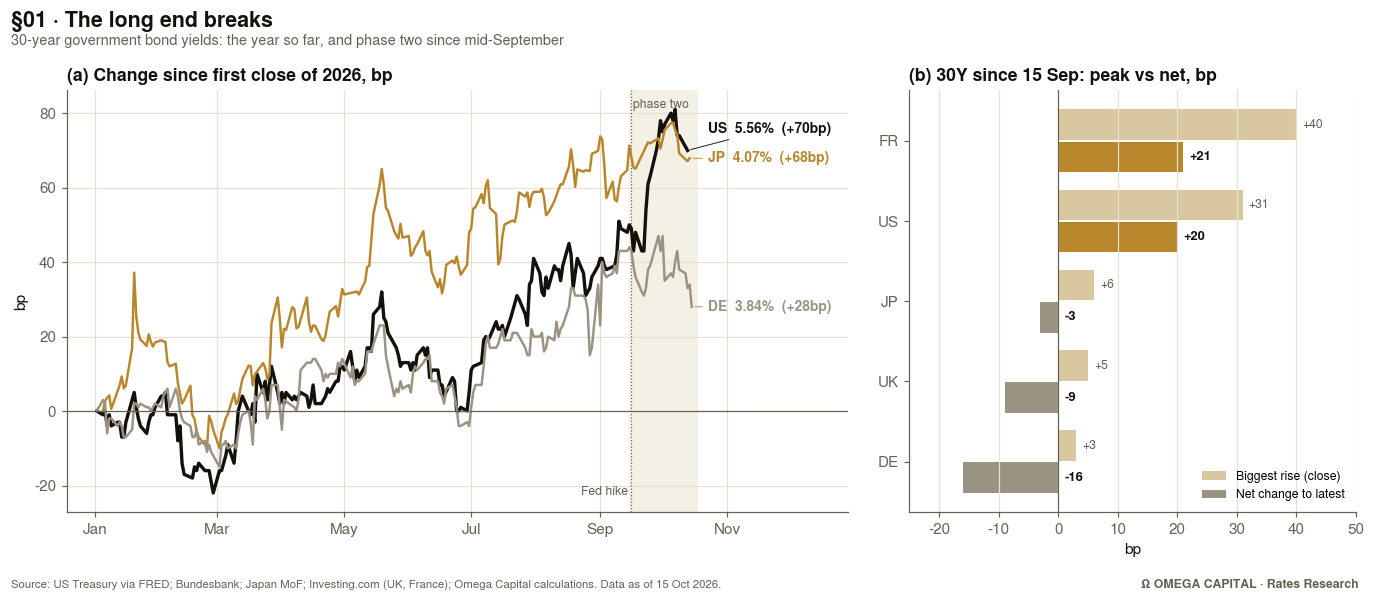

saved: charts/chart1_global_30y.png + clean copy
Price change = 30Y par bond bought at the first 2026 close, repriced at today's yield. Price only: excludes coupon income and ageing.


,1st 2026 close (%),Latest (%),Change (bp),2026 high (%),High on,Mod. duration (yrs),30Y par bond price chg (%)
Market,,,,,,,
US,4.86,5.56,70,5.67,2026-10-07,15.7,-10.2
JP,3.39,4.07,68,4.17,2026-10-06,18.7,-11.7
DE,3.56,3.84,28,4.03,2026-09-29,18.3,-5.0


Phase two (since 2026-09-15), 30Y closes:


,15 Sep (%),Latest (%),Peak rise (bp),Peak on,Net change (bp)
Market,,,,,
DE,4.00,3.84,3,2026-09-29,-16
UK,5.92,5.84,5,2026-10-07,-9
JP,4.11,4.07,6,2026-10-06,-3
US,5.36,5.56,31,2026-10-07,20
FR,5.14,5.35,40,2026-10-01,21


In [3]:
LONG = {"US": "US_30Y", "JP": "JP_30Y", "DE": "DE_30Y", "FR": "FR_30Y", "UK": "UK_30Y"}
LONG = {k: v for k, v in LONG.items() if v in px}
YTD_OK = {k: v for k, v in LONG.items() if v in FULL}          # year-to-date only where history is complete

def bond_price(coupon, y, n=30, f=2):
    """Price per 100 of an n-year bullet bond, coupon and yield as decimals, f payments per year."""
    t = np.arange(1, n * f + 1)
    return np.sum(coupon / f * 100 / (1 + y / f) ** t) + 100 / (1 + y / f) ** (n * f)

def mod_duration(y, n=30, f=2, h=1e-4):
    return -(bond_price(y, y + h, n, f) - bond_price(y, y - h, n, f)) / (2 * h * 100)

fig, (ax, axb) = plt.subplots(1, 2, figsize=(12.5, 5.3), gridspec_kw={"width_ratios": [1.75, 1]})
phase_two(ax)
ax.axvline(pd.Timestamp("2026-09-16"), color=COL["muted"], lw=0.8, ls=":")
ax.text(pd.Timestamp("2026-09-16"), 0.04, "Fed hike ", transform=ax.get_xaxis_transform(),
        fontsize=8, color=COL["muted"], ha="right")
rows, ends = [], []
for cc, col in YTD_OK.items():
    s = px[col].loc[BASE:].dropna()
    chg = (s - s.iloc[0]) * 100
    ax.plot(chg.index, chg, color=COL[cc], lw=2.2 if cc == "US" else 1.6)
    ends.append([cc, chg.index[-1], chg.iloc[-1], s.iloc[-1]])
    p_now = bond_price(s.iloc[0] / 100, s.iloc[-1] / 100)
    rows.append({"Market": cc, "1st 2026 close (%)": round(s.iloc[0], 2),
                 "Latest (%)": round(s.iloc[-1], 2), "Change (bp)": round(chg.iloc[-1]),
                 "2026 high (%)": round(s.max(), 2), "High on": s.idxmax().date(),
                 "Mod. duration (yrs)": round(mod_duration(s.iloc[0] / 100), 1),
                 "30Y par bond price chg (%)": round(p_now - 100, 1)})
ax.axhline(0, color=COL["muted"], lw=0.8)
lo, hi = ax.get_ylim(); gap = 0.07 * (hi - lo)
ends.sort(key=lambda e: e[2]); pos = [e[2] for e in ends]
for i in range(1, len(pos)):
    pos[i] = max(pos[i], pos[i - 1] + gap)
for (cc, x, yv, lvl), yl in zip(ends, pos):
    ax.annotate(f"{cc}  {lvl:.2f}%  ({yv:+.0f}bp)", xy=(x, yv), xytext=(px.index.max() + pd.Timedelta(days=8), yl),
                color=COL[cc], fontsize=9, weight="bold", va="center",
                arrowprops=dict(arrowstyle="-", color=COL[cc], lw=0.6))
ax.set_xlim(right=px.index.max() + pd.Timedelta(days=75))
ax.set_ylabel("bp"); month_axis(ax)
ax.set_title("(a) Change since first close of 2026, bp")

sb = []
for cc, col in LONG.items():
    s = px[col].loc[P2:].dropna()
    sb.append({"Market": cc, "15 Sep (%)": round(s.iloc[0], 2), "Latest (%)": round(s.iloc[-1], 2),
               "Peak rise (bp)": round((s.max() - s.iloc[0]) * 100), "Peak on": s.idxmax().date(),
               "Net change (bp)": round((s.iloc[-1] - s.iloc[0]) * 100)})
phase2 = pd.DataFrame(sb).set_index("Market").sort_values("Net change (bp)")
yy = np.arange(len(phase2))
axb.barh(yy + 0.2, phase2["Peak rise (bp)"], height=0.38, color=COL["light"], label="Biggest rise (close)")
axb.barh(yy - 0.2, phase2["Net change (bp)"], height=0.38,
         color=[COL["accent"] if v > 0 else COL["DE"] for v in phase2["Net change (bp)"]], label="Net change to latest")
for y_, (pk, nt) in enumerate(zip(phase2["Peak rise (bp)"], phase2["Net change (bp)"])):
    axb.text(pk + 1, y_ + 0.2, f"{pk:+d}", va="center", fontsize=8, color=COL["muted"])
    axb.text(max(nt, 0) + 1, y_ - 0.2, f"{nt:+d}", va="center", fontsize=8.5, weight="bold", color=COL["ink"])
axb.set_yticks(yy, phase2.index); axb.axvline(0, color=COL["muted"], lw=0.8)
axb.set_xlim(min(-25, phase2["Net change (bp)"].min() - 5), phase2["Peak rise (bp)"].max() + 10)
axb.grid(axis="y", visible=False); axb.set_xlabel("bp")
axb.legend(fontsize=8, loc="lower right")
axb.set_title(f"(b) 30Y since {pd.Timestamp(P2):%d %b}: peak vs net, bp")

header(fig, "§01 · The long end breaks", "30-year government bond yields: the year so far, and phase two since mid-September")
finish(fig, "chart1_global_30y", "US Treasury via FRED; Bundesbank; Japan MoF; Investing.com (UK, France)")

table1 = pd.DataFrame(rows).set_index("Market").sort_values("Change (bp)", ascending=False)
print("Price change = 30Y par bond bought at the first 2026 close, repriced at today's yield. "
      "Price only: excludes coupon income and ageing.")
display(table1)
print(f"Phase two (since {P2}), 30Y closes:"); display(phase2)

### §02 · The US move in two phases
Phase one (first 2026 close to 15 September) against phase two (15 September to latest), by tenor. A policy repricing moves the front end and belly most; a term-premium move shows up at the long end.

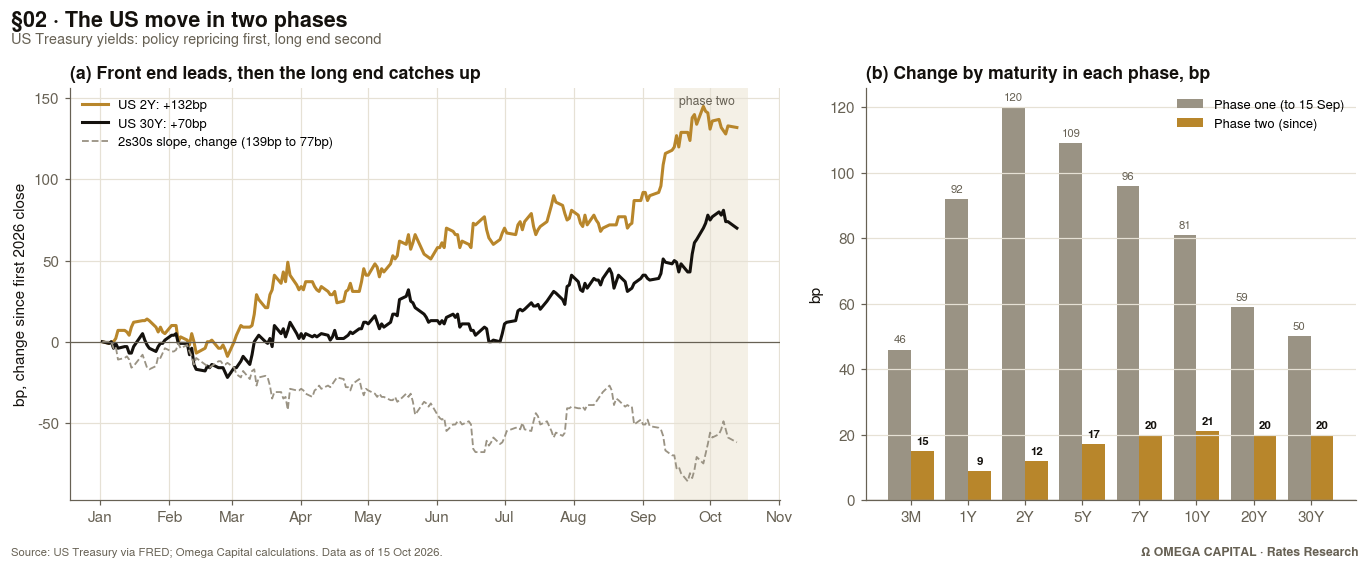

saved: charts/chart2_two_phases.png + clean copy


,3M,1Y,2Y,5Y,7Y,10Y,20Y,30Y
Phase one (bp),46.0,92.0,120.0,109.0,96.0,81.0,59.0,50.0
Phase two (bp),15.0,9.0,12.0,17.0,20.0,21.0,20.0,20.0
2026 total (bp),61.0,101.0,132.0,126.0,116.0,102.0,79.0,70.0


,02 Jan,15 Sep,13 Oct
2s10s,72.0,33.0,42.0
2s30s,139.0,69.0,77.0
5s30s,112.0,53.0,56.0


In [4]:
US_T = ["US_3M", "US_1Y", "US_2Y", "US_5Y", "US_7Y", "US_10Y", "US_20Y", "US_30Y"]
LAB = ["3M", "1Y", "2Y", "5Y", "7Y", "10Y", "20Y", "30Y"]
curve = px[US_T].dropna()
c0, cP, cE = curve.loc[BASE:].iloc[0], curve.loc[:P2].iloc[-1], curve.iloc[-1]
ph1, ph2 = (cP - c0) * 100, (cE - cP) * 100

fig, (ax, axb) = plt.subplots(1, 2, figsize=(12.5, 5.0), gridspec_kw={"width_ratios": [1.45, 1]})
phase_two(ax)
for col, c, lbl, lw in [("US_2Y", COL["accent"], "2Y", 2.0), ("US_30Y", COL["ink"], "30Y", 2.0)]:
    s = curve[col].loc[BASE:]; chg = (s - s.iloc[0]) * 100
    ax.plot(chg.index, chg, color=c, lw=lw, label=f"US {lbl}: {chg.iloc[-1]:+.0f}bp")
sl = (curve["US_30Y"] - curve["US_2Y"]).loc[BASE:] * 100
ax.plot(sl.index, sl - sl.iloc[0], color=COL["DE"], lw=1.2, ls="--", label=f"2s30s slope, change ({sl.iloc[0]:.0f}bp to {sl.iloc[-1]:.0f}bp)")
ax.axhline(0, color=COL["muted"], lw=0.8); ax.set_ylabel("bp, change since first 2026 close")
ax.legend(fontsize=8.5, loc="upper left"); month_axis(ax)
ax.set_title("(a) Front end leads, then the long end catches up")

x = np.arange(len(LAB))
axb.bar(x - 0.2, ph1, width=0.4, color=COL["DE"], label=f"Phase one (to {pd.Timestamp(P2):%d %b})")
axb.bar(x + 0.2, ph2, width=0.4, color=COL["accent"], label="Phase two (since)")
for xi, v in zip(x, ph1):
    axb.text(xi - 0.2, v + 2, f"{v:.0f}", ha="center", fontsize=7.5, color=COL["muted"])
for xi, v in zip(x, ph2):
    axb.text(xi + 0.2, v + 2, f"{v:.0f}", ha="center", fontsize=7.5, color=COL["ink"], weight="bold")
axb.set_xticks(x, LAB); axb.axhline(0, color=COL["muted"], lw=0.8); axb.set_ylabel("bp")
axb.grid(axis="x", visible=False); axb.legend(fontsize=8.5, loc="upper right")
axb.set_title("(b) Change by maturity in each phase, bp")

header(fig, "§02 · The US move in two phases", "US Treasury yields: policy repricing first, long end second")
finish(fig, "chart2_two_phases", "US Treasury via FRED")

spreads = pd.DataFrame({lbl: {"2s10s": (c["US_10Y"] - c["US_2Y"]) * 100, "2s30s": (c["US_30Y"] - c["US_2Y"]) * 100,
                              "5s30s": (c["US_30Y"] - c["US_5Y"]) * 100}
                        for lbl, c in [(f"{c0.name:%d %b}", c0), (f"{cP.name:%d %b}", cP), (f"{cE.name:%d %b}", cE)]}).round(0)
phases = pd.DataFrame({"Phase one (bp)": ph1.values, "Phase two (bp)": ph2.values, "2026 total (bp)": (ph1 + ph2).values},
                      index=LAB).round(0)
display(phases.T); display(spreads)

### §03 · Under the hood: PCA of the US Treasury curve
Principal components of daily yield changes (8 tenors, 2016–today).
- **PC1 (level):** the whole curve moves together.
- **PC2 (slope):** the long end moves against the short end.
- **PC3 (curvature):** the belly moves against both wings.

Panel (b) rebuilds the actual 2026 move by tenor from the components: level alone, then level plus slope.

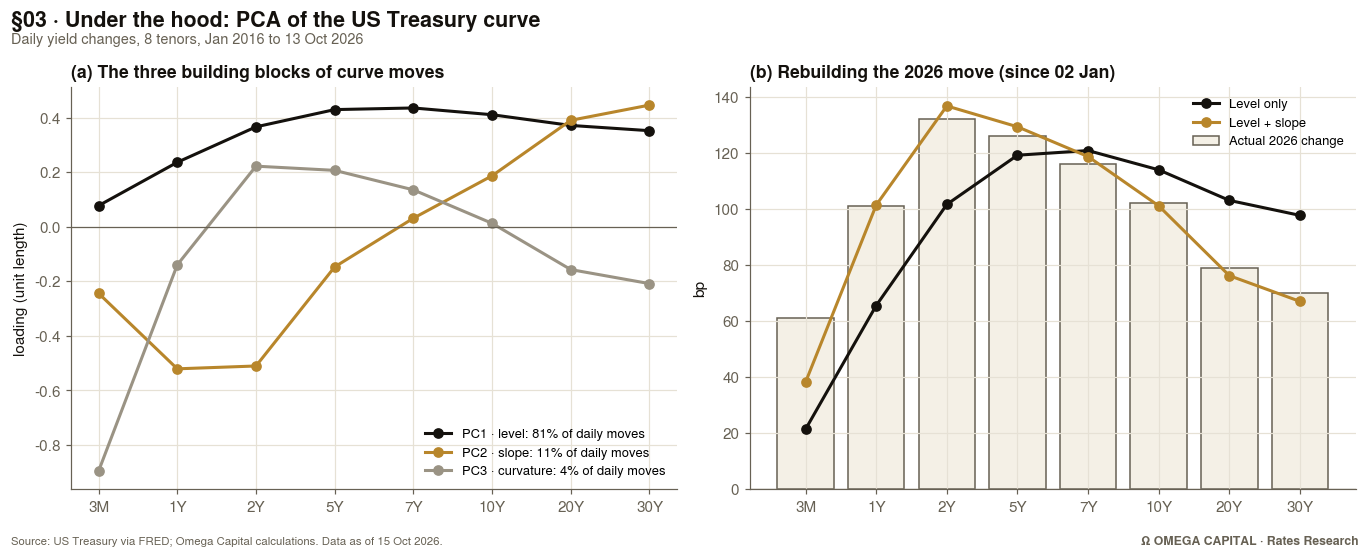

saved: charts/chart3_us_pca.png + clean copy
Loadings (unit-length eigenvectors):


,PC1 · level,PC2 · slope,PC3 · curvature
3M,0.077,-0.244,-0.896
1Y,0.236,-0.521,-0.140
2Y,0.366,-0.510,0.222
5Y,0.429,-0.147,0.207
7Y,0.435,0.031,0.135
10Y,0.411,0.187,0.012
20Y,0.371,0.390,-0.157
30Y,0.352,0.446,-0.209



Attribution of the 2026 move (bp), since 2026-01-02:


,2Y,10Y,30Y,2s30s (30Y-2Y)
PC1 · level,101.5,113.9,97.6,-3.9
PC2 · slope,35.1,-12.8,-30.7,-65.7
PC3 · curvature,-5.2,-0.3,4.9,10.1
Residual (PC4-8),0.6,1.3,-1.9,-2.4
Actual,132.0,102.0,70.0,-62.0


PC1 share: full sample 81.2% | latest 120-day window 83.2% | 2026 average 83.9%


In [5]:
US_T = ["US_3M", "US_1Y", "US_2Y", "US_5Y", "US_7Y", "US_10Y", "US_20Y", "US_30Y"]
LAB = ["3M", "1Y", "2Y", "5Y", "7Y", "10Y", "20Y", "30Y"]
curve = px[US_T].dropna()
dY = curve.diff().dropna() * 100                     # daily changes, bp

def pca(X):
    cov = np.cov(X, rowvar=False)
    w, V = np.linalg.eigh(cov)
    o = w.argsort()[::-1]; w, V = w[o], V[:, o]
    if V[:, 0].sum() < 0: V[:, 0] *= -1                                  # level: positive
    if V[-1, 1] < V[0, 1]: V[:, 1] *= -1                                 # slope: long end up
    if V[3:5, 2].mean() < (V[0, 2] + V[-1, 2]) / 2: V[:, 2] *= -1        # curvature: belly up
    return w, V

w, V = pca(dY.values)
share = w / w.sum()

# rolling 120-day share of variance explained by PC1
WIN = 120
X = dY.values
roll = pd.Series([np.linalg.eigvalsh(np.cov(X[i - WIN:i], rowvar=False))[::-1][0] /
                  np.trace(np.cov(X[i - WIN:i], rowvar=False)) for i in range(WIN, len(X) + 1)],
                 index=dY.index[WIN - 1:])

# 2026 decomposition: cumulative change by tenor projected on the PCs (exact with all 8)
start = curve.loc[BASE:].index[0]
delta = (curve.iloc[-1] - curve.loc[start]).values * 100
scores = V.T @ delta
contrib = {f"PC{k+1}": scores[k] * V[:, k] for k in range(3)}

fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.9))
names = ["PC1 · level", "PC2 · slope", "PC3 · curvature"]
cols = [COL["ink"], COL["accent"], COL["DE"]]

ax = axs[0]
for k in range(3):
    ax.plot(LAB, V[:, k], marker="o", color=cols[k], lw=2, label=f"{names[k]}: {share[k]:.0%} of daily moves")
ax.axhline(0, color=COL["muted"], lw=0.8)
ax.set_title("(a) The three building blocks of curve moves"); ax.legend(fontsize=8.5)
ax.set_ylabel("loading (unit length)")

ax = axs[1]
ax.bar(LAB, delta, color=COL["shade"], edgecolor=COL["muted"], label="Actual 2026 change")
ax.plot(LAB, contrib["PC1"], marker="o", color=cols[0], lw=2, label="Level only")
ax.plot(LAB, contrib["PC1"] + contrib["PC2"], marker="o", color=cols[1], lw=2, label="Level + slope")
ax.axhline(0, color=COL["muted"], lw=0.8); ax.set_ylabel("bp")
ax.set_title(f"(b) Rebuilding the 2026 move (since {start:%d %b})"); ax.legend(fontsize=8.5, loc="upper right")

header(fig, "§03 · Under the hood: PCA of the US Treasury curve",
       f"Daily yield changes, 8 tenors, {dY.index[0]:%b %Y} to {dY.index[-1]:%d %b %Y}")
finish(fig, "chart3_us_pca", "US Treasury via FRED")

# tables
load_tbl = pd.DataFrame(V[:, :3], index=LAB, columns=names).round(3)
idx = {t: LAB.index(t) for t in ["2Y", "10Y", "30Y"]}
attr = pd.DataFrame({n: {"2Y": c[idx["2Y"]], "10Y": c[idx["10Y"]], "30Y": c[idx["30Y"]],
                         "2s30s (30Y-2Y)": c[idx["30Y"]] - c[idx["2Y"]]}
                     for n, c in zip(names, contrib.values())}).T
attr.loc["Residual (PC4-8)"] = [delta[idx["2Y"]], delta[idx["10Y"]], delta[idx["30Y"]],
                                delta[idx["30Y"]] - delta[idx["2Y"]]] - attr.sum().values
attr.loc["Actual"] = [delta[idx["2Y"]], delta[idx["10Y"]], delta[idx["30Y"]], delta[idx["30Y"]] - delta[idx["2Y"]]]
print("Loadings (unit-length eigenvectors):"); display(load_tbl)
print(f"\nAttribution of the 2026 move (bp), since {start.date()}:"); display(attr.round(1))
print(f"PC1 share: full sample {share[0]:.1%} | latest {WIN}-day window {roll.iloc[-1]:.1%} | "
      f"2026 average {roll.loc[BASE:].mean():.1%}")

### §04 · Europe since mid-September: France against the Bund
Only the window where all series exist (from 15 September). **(a)** 10Y yield changes for France, Italy and Germany. **(b)** France–Germany spreads at 2Y and 10Y. **(c)** France minus Italy at 10Y.

*Methodology note:* Germany comes from the Bundesbank Svensson zero-coupon curve, while France and Italy are Investing.com benchmark yields. Levels can differ by a few bp because of method, but the moves are comparable.

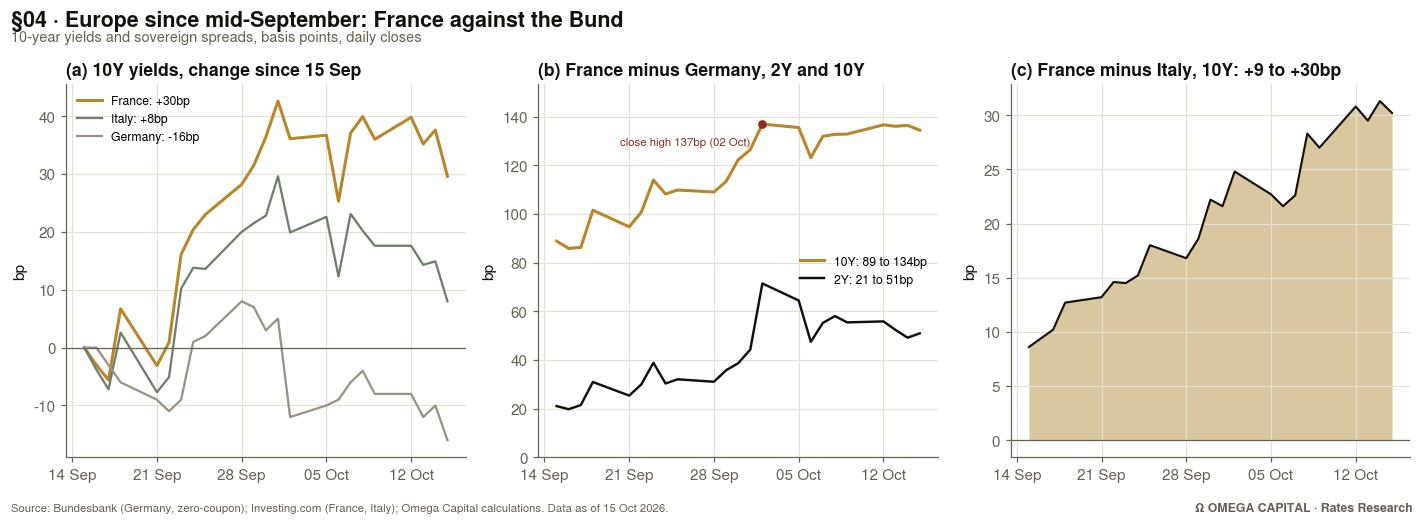

saved: charts/chart4_europe.png + clean copy


,15 Sep,Close high,High on,Latest
10Y France - Germany,89.0,137.0,2026-10-02,134.0
2Y France - Germany,21.0,71.0,2026-10-02,51.0
10Y France - Italy,9.0,31.0,2026-10-14,30.0


Yield change since 15 Sep (bp):


,bp
DE_10Y,-16.0
DE_2Y,-19.0
FR_10Y,30.0
FR_2Y,11.0
IT_10Y,8.0


In [6]:
need = {"FR_10Y", "DE_10Y", "FR_2Y", "DE_2Y", "IT_10Y"}
assert need <= set(px.columns), f"missing: {need - set(px.columns)}"

eu = px[sorted(need)].loc[P2:].dropna()
s10 = (eu["FR_10Y"] - eu["DE_10Y"]) * 100
s2 = (eu["FR_2Y"] - eu["DE_2Y"]) * 100
fi = (eu["FR_10Y"] - eu["IT_10Y"]) * 100

fig, axs = plt.subplots(1, 3, figsize=(13, 4.6))
ax = axs[0]
for col, cc, lbl in [("FR_10Y", "FR", "France"), ("IT_10Y", "IT", "Italy"), ("DE_10Y", "DE", "Germany")]:
    chg = (eu[col] - eu[col].iloc[0]) * 100
    ax.plot(chg.index, chg, color=COL[cc], lw=2 if cc == "FR" else 1.5, label=f"{lbl}: {chg.iloc[-1]:+.0f}bp")
ax.axhline(0, color=COL["muted"], lw=0.8); ax.set_ylabel("bp"); ax.legend(fontsize=8, loc="upper left")
ax.set_title("(a) 10Y yields, change since 15 Sep"); day_axis(ax)

ax = axs[1]
ax.plot(s10.index, s10, color=COL["FR"], lw=2, label=f"10Y: {s10.iloc[0]:.0f} to {s10.iloc[-1]:.0f}bp")
ax.plot(s2.index, s2, color=COL["ink"], lw=1.6, label=f"2Y: {s2.iloc[0]:.0f} to {s2.iloc[-1]:.0f}bp")
ax.scatter([s10.idxmax()], [s10.max()], color=COL["UK"], zorder=5, s=22)
ax.annotate(f"close high {s10.max():.0f}bp ({s10.idxmax():%d %b})", xy=(s10.idxmax(), s10.max()),
            xytext=(-8, -14), textcoords="offset points", fontsize=7.5, color=COL["UK"], ha="right")
ax.set_ylabel("bp"); ax.set_ylim(0, s10.max() * 1.12); ax.legend(fontsize=8, loc="center right")
ax.set_title("(b) France minus Germany, 2Y and 10Y"); day_axis(ax)

ax = axs[2]
ax.fill_between(fi.index, 0, fi, color=COL["light"], lw=0)
ax.plot(fi.index, fi, color=COL["ink"], lw=1.4)
ax.axhline(0, color=COL["muted"], lw=0.8); ax.set_ylabel("bp")
ax.set_title(f"(c) France minus Italy, 10Y: {fi.iloc[0]:+.0f} to {fi.iloc[-1]:+.0f}bp"); day_axis(ax)

header(fig, "§04 · Europe since mid-September: France against the Bund",
       "10-year yields and sovereign spreads, basis points, daily closes")
finish(fig, "chart4_europe", "Bundesbank (Germany, zero-coupon); Investing.com (France, Italy)")

tbl3 = pd.DataFrame({
    "15 Sep": [s10.iloc[0], s2.iloc[0], fi.iloc[0]],
    "Close high": [s10.max(), s2.max(), fi.max()],
    "High on": [s10.idxmax().date(), s2.idxmax().date(), fi.idxmax().date()],
    "Latest": [s10.iloc[-1], s2.iloc[-1], fi.iloc[-1]],
}, index=["10Y France - Germany", "2Y France - Germany", "10Y France - Italy"]).round(0)
display(tbl3)
eu_chg = ((eu.iloc[-1] - eu.iloc[0]) * 100).round(0)
print("Yield change since 15 Sep (bp):"); display(eu_chg.to_frame("bp"))

### §05 · Volatility regimes
- **Realised volatility:** the rolling 20-day standard deviation of daily bp changes, annualised (×√252).
- **Regime model:** a 2-state Markov-switching model on daily US 10Y changes, with a constant mean and switching variance:
  $\Delta y_t = \mu_{s_t} + \varepsilon_t$, where $\varepsilon_t \sim N(0, \sigma^2_{s_t})$ and $s_t \in \{\text{calm}, \text{stressed}\}$ follows a first-order Markov chain.

Shaded periods are days when the smoothed probability of the stressed regime is above 50%.

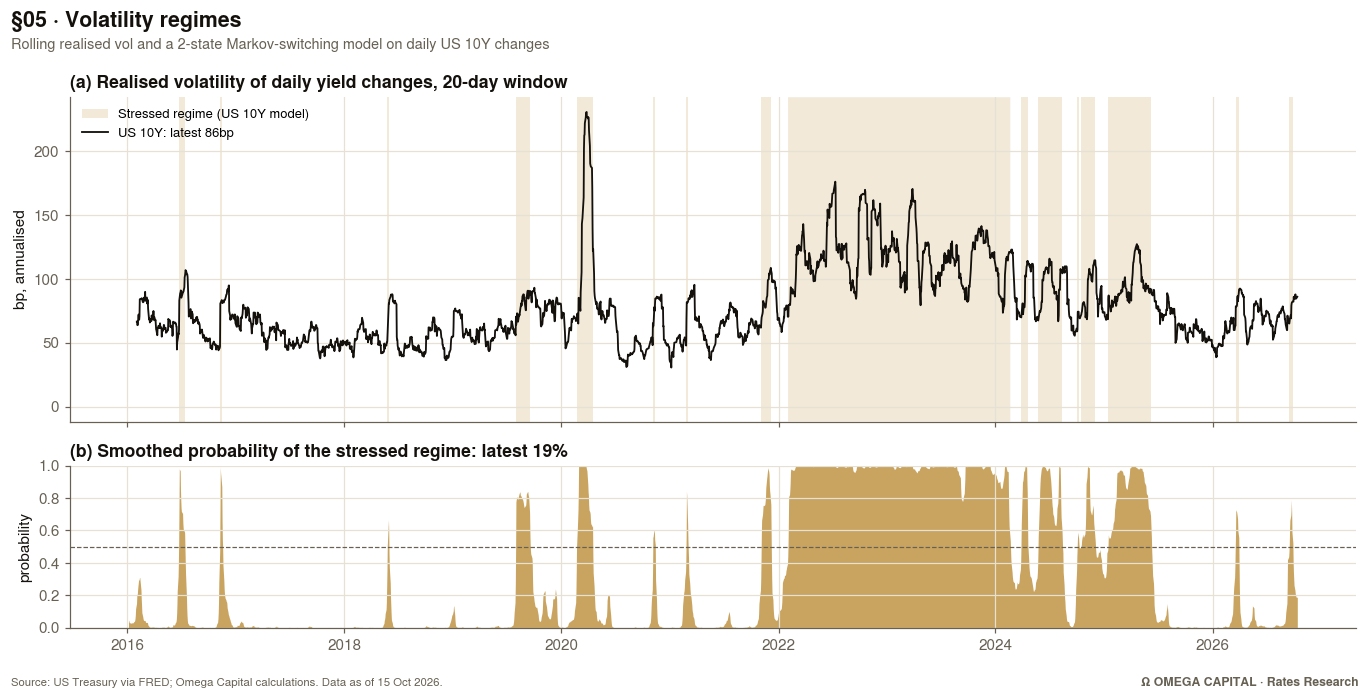

saved: charts/chart5_vol_regimes.png + clean copy


,Daily vol (bp),Annualised vol (bp),Persistence Pr(stay),Expected duration (days),Share of days since 2016,Share of 2026 days
Calm,3.84,61.0,0.99,101.9,0.679,0.913
Stressed,7.39,117.0,0.98,49.0,0.321,0.087


Log-likelihood -8101.7 | AIC 16215.4 | n = 2694
US 10Y realised vol: Jan 2026 average 46bp | latest 86bp | 2022-23 range 89-155bp (10th-90th pct)
Stress episodes in 2026 (prob > 50%):
  19 Mar to 30 Mar (8 days), peak prob 73%
  16 Sep to 28 Sep (9 days), peak prob 79%


In [7]:
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression

def rv(s, w=20):
    d = s.dropna().diff() * 100
    return d.rolling(w).std() * np.sqrt(252)

y = (px["US_10Y"].dropna().diff() * 100).dropna()
res = MarkovRegression(y.values, k_regimes=2, trend="c", switching_variance=True).fit(disp=False, search_reps=10)
names_ = list(res.model.param_names)
sig2 = np.asarray(res.params)[[i for i, n in enumerate(names_) if n.startswith("sigma2")]]
hi = int(np.argmax(sig2)); lo_ = 1 - hi
prob = pd.Series(np.asarray(res.smoothed_marginal_probabilities)[:, hi], index=y.index)
P = res.regime_transition[:, :, 0]                       # P[i, j] = Pr(s_t = i | s_t-1 = j)
stay_hi, stay_lo = P[hi, hi], P[lo_, lo_]

fig, axs = plt.subplots(2, 1, figsize=(12.5, 6.2), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax = axs[0]
ax.fill_between(prob.index, 0, 1, where=prob > 0.5, transform=ax.get_xaxis_transform(),
                color=COL["accent"], alpha=0.18, lw=0, label="Stressed regime (US 10Y model)")
r = rv(px["US_10Y"]); ax.plot(r.index, r, color=COL["ink"], lw=1.2, label=f"US 10Y: latest {r.iloc[-1]:.0f}bp")
ax.set_ylabel("bp, annualised"); ax.legend(loc="upper left", fontsize=8.5)
ax.set_title("(a) Realised volatility of daily yield changes, 20-day window")

ax = axs[1]
ax.fill_between(prob.index, 0, prob, color=COL["accent"], alpha=0.75, lw=0)
ax.axhline(0.5, color=COL["muted"], ls="--", lw=0.8)
ax.set_ylim(0, 1); ax.set_ylabel("probability")
ax.set_title(f"(b) Smoothed probability of the stressed regime: latest {prob.iloc[-1]:.0%}")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

header(fig, "§05 · Volatility regimes",
       "Rolling realised vol and a 2-state Markov-switching model on daily US 10Y changes")
finish(fig, "chart5_vol_regimes", "US Treasury via FRED")

ann = np.sqrt(sig2 * 252)
tbl4 = pd.DataFrame({
    "Daily vol (bp)": np.sqrt(sig2)[[lo_, hi]].round(2),
    "Annualised vol (bp)": ann[[lo_, hi]].round(0),
    "Persistence Pr(stay)": [round(stay_lo, 3), round(stay_hi, 3)],
    "Expected duration (days)": [round(1 / (1 - stay_lo), 1), round(1 / (1 - stay_hi), 1)],
    "Share of days since 2016": [round((prob <= 0.5).mean(), 3), round((prob > 0.5).mean(), 3)],
    "Share of 2026 days": [round((prob.loc[BASE:] <= 0.5).mean(), 3), round((prob.loc[BASE:] > 0.5).mean(), 3)],
}, index=["Calm", "Stressed"])
display(tbl4)
print(f"Log-likelihood {res.llf:.1f} | AIC {res.aic:.1f} | n = {res.nobs}")
rv10 = rv(px["US_10Y"])
print(f"US 10Y realised vol: Jan 2026 average {rv10.loc['2026-01'].mean():.0f}bp | latest {rv10.iloc[-1]:.0f}bp | "
      f"2022-23 range {rv10.loc['2022':'2023'].quantile(0.1):.0f}-{rv10.loc['2022':'2023'].quantile(0.9):.0f}bp (10th-90th pct)")
print(f"Stress episodes in 2026 (prob > 50%):")
st = (prob.loc[BASE:] > 0.5).astype(int); grp = (st.diff() != 0).cumsum()
for _, g in st[st == 1].groupby(grp[st == 1]):
    print(f"  {g.index[0]:%d %b} to {g.index[-1]:%d %b} ({len(g)} days), peak prob {prob.loc[g.index].max():.0%}")

### §06 · Oil and yields
How sensitive is the US 10Y to oil? We regress the daily change in the 10Y yield (bp) on Brent's daily log return (%) over a rolling 60-day window:
$\Delta y_t = \alpha + \beta\, r^{oil}_t + \varepsilon_t$.

β is the bp move in the 10Y for a +1% move in Brent. The band is a 95% confidence interval.

In [8]:
# the rolling beta needs years of Brent history; skip cleanly until the full download is in data/
oil_ok = "BRENT" in px and "BRENT" not in short and px["BRENT"].count() > 500
if not oil_ok:
    print("Brent history too short for a rolling 60-day beta: §06 chart skipped until the full Investing.com download.")
else:
    oil = px["BRENT"].dropna(); oil = oil[oil > 0]
    df = pd.concat({"r_oil": np.log(oil).diff() * 100, "dy": px["US_10Y"].dropna().diff() * 100}, axis=1).dropna()
    # drop extreme oil days (futures roll artefacts / April 2020): keep |r| < 15%
    df = df[df["r_oil"].abs() < 15]

    W = 60
    cov = df["dy"].rolling(W).cov(df["r_oil"]); var = df["r_oil"].rolling(W).var()
    beta = cov / var
    rho = df["dy"].rolling(W).corr(df["r_oil"])
    se = np.sqrt((1 - rho ** 2) / (W - 2)) * df["dy"].rolling(W).std() / df["r_oil"].rolling(W).std()

    def ols_beta(d):
        b = np.cov(d["dy"], d["r_oil"])[0, 1] / d["r_oil"].var()
        r = d["dy"].corr(d["r_oil"]); n = len(d)
        s = np.sqrt((1 - r ** 2) / (n - 2)) * d["dy"].std() / d["r_oil"].std()
        return b, s, r, n

    fig, axs = plt.subplots(2, 1, figsize=(12, 7.8), gridspec_kw={"height_ratios": [1, 1]})
    ax = axs[0]; lv = px[["US_10Y", "BRENT"]].loc["2025":]
    ax.plot(lv.index, lv["US_10Y"].ffill(), color=COL["US"], lw=1.6, label="US 10Y yield (lhs, %)")
    ax.set_ylabel("US 10Y yield, %", color=COL["US"], weight="bold")
    ax2 = ax.twinx(); ax2.grid(False); ax2.spines["right"].set_visible(True)
    ax2.plot(lv.index, lv["BRENT"].ffill(), color=COL["BRENT"], lw=1.4, label="Brent front-month (rhs, $/bbl)")
    ax2.set_ylabel("Brent front-month, $/bbl", color=COL["BRENT"], weight="bold")
    ax.set_title("(a) Levels since 2025"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))

    ax = axs[1]; b = beta.loc["2019":]; s_ = se.loc["2019":]
    ax.fill_between(b.index, b - 1.96 * s_, b + 1.96 * s_, color=COL["BRENT"], alpha=0.18, label="95% CI")
    ax.plot(b.index, b, color=COL["BRENT"], lw=1.4, label=f"rolling {W}d β: latest {beta.iloc[-1]:.2f}")
    ax.axhline(0, color=COL["muted"], lw=0.8)
    ax.set_ylabel("bp per +1% Brent"); ax.legend(loc="lower left", fontsize=8.5, ncol=2)
    ax.set_title("(b) Sensitivity of US 10Y daily changes to Brent returns")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    header(fig, "§06 · Oil and yields", "Rolling regression of daily ΔUS 10Y (bp) on daily Brent log returns (%)")
    finish(fig, "chart6_oil_yields", "US Treasury via FRED; Investing.com (Brent futures)")

    out = []
    for lbl, d in [("2016–2025", df.loc[:"2025"]), ("2026 YTD", df.loc[BASE:]), (f"Last {W} days", df.iloc[-W:])]:
        b_, s__, r_, n_ = ols_beta(d)
        out.append({"Window": lbl, "β (bp per 1%)": round(b_, 2), "t-stat": round(b_ / s__, 1),
                    "corr": round(r_, 2), "n": n_})
    display(pd.DataFrame(out).set_index("Window"))

Brent history too short for a rolling 60-day beta: §06 chart skipped until the full Investing.com download.


### Headline numbers for the report text

In [9]:
def ytd(col):
    s = px[col].loc[BASE:].dropna(); return (s.iloc[-1] - s.iloc[0]) * 100

us = px[US_T].dropna()
c0, c1 = us.loc[BASE:].iloc[0], us.iloc[-1]
lines = [
    f"US 10Y: {c1['US_10Y']:.2f}% ({ytd('US_10Y'):+.0f}bp YTD); 2026 high {px['US_10Y'].loc[BASE:].max():.2f}% on {px['US_10Y'].loc[BASE:].idxmax():%d %b}",
    f"US 2Y: {c1['US_2Y']:.2f}% ({ytd('US_2Y'):+.0f}bp YTD); US 30Y {c1['US_30Y']:.2f}% ({ytd('US_30Y'):+.0f}bp)",
    f"US curve 2s10s / 2s30s / 5s30s: " + " | ".join(f"{k} {spreads.loc[k].iloc[0]:+.0f} -> {spreads.loc[k].iloc[1]:+.0f} -> {spreads.loc[k].iloc[2]:+.0f}bp" for k in spreads.index),
    f"US phases (2Y / 30Y): phase one {phases.loc['2Y', 'Phase one (bp)']:+.0f} / {phases.loc['30Y', 'Phase one (bp)']:+.0f}bp; "
    f"phase two {phases.loc['2Y', 'Phase two (bp)']:+.0f} / {phases.loc['30Y', 'Phase two (bp)']:+.0f}bp",
    f"PCA: level {share[0]:.0%}, slope {share[1]:.0%}, curvature {share[2]:.0%} of daily US curve moves since 2016; latest 120d PC1 {roll.iloc[-1]:.0%}",
    f"PCA rebuild of 30Y 2026 move: level only {contrib['PC1'][-1]:+.0f}bp, level+slope {contrib['PC1'][-1] + contrib['PC2'][-1]:+.0f}bp, actual {delta[-1]:+.0f}bp",
    f"30Y yields YTD (full history only): " + ", ".join(f"{k} {table1.loc[k, 'Change (bp)']:+d}bp" for k in table1.index),
    f"30Y par-bond price change YTD: " + ", ".join(f"{k} {table1.loc[k, '30Y par bond price chg (%)']:+.1f}%" for k in table1.index),
    f"30Y since {P2} (peak / net): " + ", ".join(f"{k} {phase2.loc[k, 'Peak rise (bp)']:+d}/{phase2.loc[k, 'Net change (bp)']:+d}bp" for k in phase2.index[::-1]),
    f"10Y since {P2}: " + ", ".join(f"{k} {v:+.0f}bp" for k, v in eu_chg[["FR_10Y", "IT_10Y", "DE_10Y"]].items()),
    f"OAT-Bund 10Y: {s10.iloc[0]:.0f} -> {s10.iloc[-1]:.0f}bp (close high {s10.max():.0f}bp on {s10.idxmax():%d %b}); "
    f"2Y {s2.iloc[0]:.0f} -> {s2.iloc[-1]:.0f}bp (high {s2.max():.0f}bp); FR-IT {fi.iloc[0]:+.0f} -> {fi.iloc[-1]:+.0f}bp",
    f"Vol regime: stressed-regime probability {prob.iloc[-1]:.0%} today; stressed on "
    f"{(prob.loc[BASE:] > 0.5).mean():.0%} of 2026 days vs {(prob > 0.5).mean():.0%} since 2016",
    f"US 10Y realised vol: latest {rv10.iloc[-1]:.0f}bp (Jan 2026 average {rv10.loc['2026-01'].mean():.0f}bp)",
]
print(f"Data as of {AS_OF}\n")
for l in lines: print("•", l)
print("\nCharts saved in:", FIG.resolve())

Data as of 2026-10-15

• US 10Y: 5.21% (+102bp YTD); 2026 high 5.31% on 05 Oct
• US 2Y: 4.79% (+132bp YTD); US 30Y 5.56% (+70bp)
• US curve 2s10s / 2s30s / 5s30s: 2s10s +72 -> +33 -> +42bp | 2s30s +139 -> +69 -> +77bp | 5s30s +112 -> +53 -> +56bp
• US phases (2Y / 30Y): phase one +120 / +50bp; phase two +12 / +20bp
• PCA: level 81%, slope 11%, curvature 4% of daily US curve moves since 2016; latest 120d PC1 83%
• PCA rebuild of 30Y 2026 move: level only +98bp, level+slope +67bp, actual +70bp
• 30Y yields YTD (full history only): US +70bp, JP +68bp, DE +28bp
• 30Y par-bond price change YTD: US -10.2%, JP -11.7%, DE -5.0%
• 30Y since 2026-09-15 (peak / net): FR +40/+21bp, US +31/+20bp, JP +6/-3bp, UK +5/-9bp, DE +3/-16bp
• 10Y since 2026-09-15: FR_10Y +30bp, IT_10Y +8bp, DE_10Y -16bp
• OAT-Bund 10Y: 89 -> 134bp (close high 137bp on 02 Oct); 2Y 21 -> 51bp (high 71bp); FR-IT +9 -> +30bp
• Vol regime: stressed-regime probability 19% today; stressed on 9% of 2026 days vs 32% since 2016
• US 